# MUSAS — Simulator Usage Guide

Este notebook mostra como construir uma simulação do zero, implementar algoritmos seguindo as interfaces do MUSAS, executar o cenário, consultar o dataset SQLite, calcular métricas e gerar visualizações.

Os algoritmos são deliberadamente simples. O objetivo é explicar os contratos e o fluxo de integração, não propor métodos de desconflitamento prontos para uso operacional.


## 1. Preparação

Este notebook deve ser executado a partir da pasta `walkthrough`. A célula abaixo apenas define onde os arquivos gerados serão salvos.


In [148]:
from pathlib import Path

OUTPUT_DIRECTORY = Path("outputs")
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
DATASET_PATH = "simulator_usage_guide.sqlite"

print("Dataset:", DATASET_PATH)

Dataset: simulator_usage_guide.sqlite


## 2. O que o usuário fornece

A `Simulation` coordena SimPy, comunicação, UAVs, FPM, SD, Tracking e TD. O usuário fornece:

1. planos de voo e espaço aéreo;
2. algoritmos de dinâmica, guidance e sensor para cada UAV;
3. algoritmos de predição e desconflitamento estratégico;
4. opcionalmente, tracking, predição tática e desconflitamento tático;
5. parâmetros temporais e caminho do dataset.

As interfaces são ABCs: uma implementação deve herdar a interface correspondente e implementar todos os métodos abstratos.


## 3. Imports


In [149]:
from dataclasses import dataclass
from itertools import combinations
from math import dist
from typing import Sequence

import matplotlib.pyplot as plt
from IPython.display import Image, display

from musas.airspace import (
    Airspace,
    Box3D,
    Cylinder3D,
    Geofence,
    Obstacle,
    WindZone,
)
from musas.algorithms.builtins import (
    FirstOrderDynamics,
    PerfectSensor,
    WaypointGuidance,
)
from musas.algorithms.interfaces import (
    ConflictPredictionAlgorithm,
    StrategicDeconflictionAlgorithm,
    TacticalConflictPredictionAlgorithm,
    TacticalDeconflictionAlgorithm,
    TrackingAlgorithm,
)
from musas.domain import (
    Conflict,
    FlightPlan,
    FlightPlanUpdate,
    PredictedState,
    StrategicDecision,
    TrackPrediction,
    TrackingReport,
    Waypoint,
)
from musas.simulation import (
    Simulation,
    SimulationDataset,
    VisualizationConfig,
    animate_dataset,
    plot_dataset,
)
from musas.simulation.metrics import calculate_metrics


## 4. Planos de voo

`Waypoint` representa posição e instante planejado. `FlightPlan` ordena os waypoints pelo tempo.

- `UAV A` e `UAV B` cruzariam a origem simultaneamente; o SD deverá modificar o segundo plano avaliado.
- `UAV C` atravessa uma região inicialmente livre. Uma geofence será ativada durante seu voo, exigindo atuação tática.
- `UAV D` possui inicialmente separação segura de C. Depois que C contorna a geofence, uma wind zone empurra D em direção à nova trajetória de C.


In [150]:
flight_plans = {
    "UAV A": FlightPlan([
        Waypoint(-80, 0, 100, 5),
        Waypoint(0, 0, 100, 15),
        Waypoint(80, 0, 100, 25),
    ]),
    "UAV B": FlightPlan([
        Waypoint(0, -80, 100, 5),
        Waypoint(0, 0, 100, 15),
        Waypoint(0, 80, 100, 25),
    ]),
    "UAV C": FlightPlan([
        Waypoint(-100, -100, 100, 10),
        Waypoint(0, -100, 100, 22.5),
        Waypoint(100, -100, 100, 35),
    ]),
    "UAV D": FlightPlan([
        Waypoint(-100, 60, 100, 10),
        Waypoint(0, 60, 100, 24),
        Waypoint(100, 60, 100, 38),
    ]),
}

for name, plan in flight_plans.items():
    print(name, "->", [waypoint.position() for waypoint in plan.waypoint_list])


UAV A -> [[-80.0, 0.0, 100.0], [0.0, 0.0, 100.0], [80.0, 0.0, 100.0]]
UAV B -> [[0.0, -80.0, 100.0], [0.0, 0.0, 100.0], [0.0, 80.0, 100.0]]
UAV C -> [[-100.0, -100.0, 100.0], [0.0, -100.0, 100.0], [100.0, -100.0, 100.0]]
UAV D -> [[-100.0, 60.0, 100.0], [0.0, 60.0, 100.0], [100.0, 60.0, 100.0]]


## 5. Função auxiliar para trajetórias planejadas

O predictor estratégico precisa comparar posições em instantes comuns. Esta interpolação pertence ao algoritmo do usuário, não ao núcleo do simulador.


In [151]:
def planned_position(flight_plan: FlightPlan, timestamp: float) -> list[float] | None:
    waypoints = flight_plan.waypoint_list
    if not waypoints or timestamp < waypoints[0].t or timestamp > waypoints[-1].t:
        return None

    for first, second in zip(waypoints, waypoints[1:]):
        if first.t <= timestamp <= second.t:
            if second.t == first.t:
                return second.position()
            fraction = (timestamp - first.t) / (second.t - first.t)
            return [
                start + fraction * (end - start)
                for start, end in zip(first.position(), second.position())
            ]
    return waypoints[-1].position()


## 6. Representações de conflito

`Conflict` é uma classe-base intencionalmente vazia. Cada família de algoritmos pode criar uma representação adequada ao seu método.


In [152]:
@dataclass(frozen=True)
class StrategicTrafficConflict(Conflict):
    other_uav: str
    timestamp: float


@dataclass(frozen=True)
class SimpleTacticalConflict(Conflict):
    kind: str
    uav_name: str
    other_id: str


## 7. Predição estratégica

O algoritmo amostra os intervalos temporais compartilhados entre a proposta e cada plano aprovado. Aqui usamos uma esfera de separação 3D.


In [153]:
class SampledStrategicPrediction(ConflictPredictionAlgorithm):
    def __init__(self, minimum_separation: float, sample_step: float = 0.5):
        self.minimum_separation = minimum_separation
        self.sample_step = sample_step

    def predict(
        self,
        proposed_flight_plan: FlightPlan,
        approved_flight_plans: dict[str, FlightPlan],
        airspace: Airspace,
    ) -> list[Conflict]:
        conflicts: list[Conflict] = []
        proposal_start = proposed_flight_plan.waypoint_list[0].t
        proposal_end = proposed_flight_plan.waypoint_list[-1].t

        for other_uav, other_plan in approved_flight_plans.items():
            start = max(proposal_start, other_plan.waypoint_list[0].t)
            end = min(proposal_end, other_plan.waypoint_list[-1].t)
            timestamp = start
            while timestamp <= end:
                proposed_position = planned_position(
                    proposed_flight_plan, timestamp
                )
                other_position = planned_position(other_plan, timestamp)
                if (
                    proposed_position is not None
                    and other_position is not None
                    and dist(proposed_position, other_position)
                    < self.minimum_separation
                ):
                    conflicts.append(
                        StrategicTrafficConflict(other_uav, timestamp)
                    )
                    break
                timestamp += self.sample_step

        return conflicts


## 8. Desconflitamento estratégico

Quando há conflito, esta implementação cria uma contraproposta deslocando todos os waypoints verticalmente. Um algoritmo real deveria também validar a nova trajetória contra todas as operações e restrições.


In [154]:
class AltitudeStrategicDeconfliction(StrategicDeconflictionAlgorithm):
    def __init__(self, altitude_offset: float = 40.0):
        self.altitude_offset = altitude_offset

    def deconflict(
        self,
        proposed_flight_plan: FlightPlan,
        conflicts: list[Conflict],
        inactive_flight_plans: dict[str, FlightPlan],
        active_flight_plans: dict[str, FlightPlan],
        airspace: Airspace,
    ) -> tuple[StrategicDecision, FlightPlan | None, list[FlightPlanUpdate]]:
        if not conflicts:
            return StrategicDecision.APPROVE, None, []

        counter_proposal = FlightPlan([
            Waypoint(
                waypoint.x,
                waypoint.y,
                waypoint.z + self.altitude_offset,
                waypoint.t,
            )
            for waypoint in proposed_flight_plan.waypoint_list
        ])
        return StrategicDecision.COUNTER_PROPOSAL, counter_proposal, []


## 9. Tracking

O tracker combina o plano de voo com o movimento observado nos reports. A trajetória planejada fornece o formato nominal da previsão, inclusive suas curvas, enquanto a diferença entre a velocidade observada e a planejada preserva desvios causados por efeitos como o vento.


In [155]:
class PlanAwareTracking(TrackingAlgorithm):
    @staticmethod
    def _planned_velocity(
        flight_plan: FlightPlan,
        timestamp: float,
        time_step: float,
    ) -> list[float] | None:
        current = planned_position(flight_plan, timestamp)
        following = planned_position(flight_plan, timestamp + time_step)
        if current is not None and following is not None:
            return [
                (future - present) / time_step
                for present, future in zip(current, following)
            ]

        previous = planned_position(flight_plan, timestamp - time_step)
        if previous is not None and current is not None:
            return [
                (present - past) / time_step
                for past, present in zip(previous, current)
            ]
        return None

    def predict(
        self,
        uav_name: str,
        report_history: Sequence[TrackingReport],
        flight_plan: FlightPlan,
        prediction_start: float,
        prediction_horizon: int,
        prediction_step: float,
    ) -> TrackPrediction:
        latest = report_history[-1]

        if len(report_history) >= 2:
            previous = report_history[-2]
            report_interval = latest.timestamp - previous.timestamp
            estimated_velocity = (
                [
                    (current - past) / report_interval
                    for current, past in zip(
                        latest.position, previous.position
                    )
                ]
                if report_interval > 0
                else list(latest.velocity)
            )
        else:
            estimated_velocity = list(latest.velocity)

        elapsed = max(0.0, prediction_start - latest.timestamp)
        estimated_position = [
            position + velocity * elapsed
            for position, velocity in zip(
                latest.position, estimated_velocity
            )
        ]

        planned_start = planned_position(flight_plan, prediction_start)
        planned_velocity = self._planned_velocity(
            flight_plan, prediction_start, prediction_step
        )
        position_error = (
            [
                estimated - planned
                for estimated, planned in zip(
                    estimated_position, planned_start
                )
            ]
            if planned_start is not None
            else [0.0, 0.0, 0.0]
        )
        velocity_error = (
            [
                observed - planned
                for observed, planned in zip(
                    estimated_velocity, planned_velocity
                )
            ]
            if planned_velocity is not None
            else [0.0, 0.0, 0.0]
        )

        predicted_states = []
        for step in range(1, prediction_horizon + 1):
            elapsed_prediction = prediction_step * step
            timestamp = prediction_start + elapsed_prediction
            planned = planned_position(flight_plan, timestamp)
            future_planned_velocity = self._planned_velocity(
                flight_plan, timestamp, prediction_step
            )

            if planned is not None:
                position = [
                    nominal + offset + drift * elapsed_prediction
                    for nominal, offset, drift in zip(
                        planned, position_error, velocity_error
                    )
                ]
                velocity = [
                    nominal + drift
                    for nominal, drift in zip(
                        future_planned_velocity
                        or planned_velocity
                        or estimated_velocity,
                        velocity_error,
                    )
                ]
            else:
                position = [
                    current + velocity * elapsed_prediction
                    for current, velocity in zip(
                        estimated_position, estimated_velocity
                    )
                ]
                velocity = estimated_velocity.copy()

            predicted_states.append(
                PredictedState(
                    position=position,
                    velocity=velocity,
                    timestamp=timestamp,
                )
            )
        return TrackPrediction(
            uav_name=uav_name,
            estimated_state=PredictedState(
                position=estimated_position,
                velocity=estimated_velocity,
                timestamp=prediction_start,
            ),
            predicted_states=tuple(predicted_states),
            generated_at=prediction_start,
        )


## 10. Predição tática

O predictor avalia periodicamente um snapshot de todas as tracks contra obstáculos, geofences ativas e os demais UAVs. Cada par de UAVs é verificado apenas uma vez. A `Simulation` entrega ao algoritmo apenas o snapshot operacional atual do espaço aéreo.


In [156]:
class SimpleTacticalPrediction(TacticalConflictPredictionAlgorithm):
    def __init__(self, minimum_separation: float = 20.0):
        self.minimum_separation = minimum_separation

    def predict(
        self,
        tracks: dict[str, TrackPrediction],
        airspace: Airspace,
    ) -> list[Conflict]:
        conflicts: list[Conflict] = []
        states_by_uav = {
            name: (track.estimated_state, *track.predicted_states)
            for name, track in tracks.items()
        }

        for uav_name, states in states_by_uav.items():
            for obstacle in airspace.obstacles.values():
                if any(
                    obstacle.contains(state.position) for state in states
                ):
                    conflicts.append(SimpleTacticalConflict(
                        "obstacle", uav_name, obstacle.obstacle_id,
                    ))

            for geofence in airspace.geofences.values():
                if any(
                    geofence.prohibits(state.position, state.timestamp)
                    for state in states
                ):
                    conflicts.append(SimpleTacticalConflict(
                        "geofence", uav_name, geofence.geofence_id,
                    ))

        for uav_name, other_name in combinations(sorted(tracks), 2):
            states = states_by_uav[uav_name]
            other_states = states_by_uav[other_name]
            conflict_found = False
            for state in states:
                closest = min(
                    other_states,
                    key=lambda other: abs(other.timestamp - state.timestamp),
                )
                if (
                    abs(closest.timestamp - state.timestamp) <= 0.5
                    and dist(state.position, closest.position)
                    < self.minimum_separation
                ):
                    conflict_found = True
                    break
            if conflict_found:
                conflicts.append(SimpleTacticalConflict(
                    "traffic",
                    uav_name,
                    other_name,
                ))

        return conflicts


## 11. Desconflitamento tático

O TD devolve `FlightPlanUpdate`s; o FPM armazena e envia os novos planos. Para geofences cilíndricas, o exemplo cria um desvio lateral. Para tráfego, cria uma manobra vertical. O conjunto `_handled` evita repetir a mesma manobra neste cenário didático.


In [157]:
class SimpleTacticalDeconfliction(TacticalDeconflictionAlgorithm):
    def __init__(self):
        self._handled: set[tuple[str, str, str]] = set()

    def deconflict(
        self,
        conflicts: list[Conflict],
        tracks: dict[str, TrackPrediction],
        flight_plans: dict[str, FlightPlan],
        airspace: Airspace,
    ) -> list[FlightPlanUpdate]:
        updates: list[FlightPlanUpdate] = []

        for conflict in conflicts:
            if not isinstance(conflict, SimpleTacticalConflict):
                continue
            key = (conflict.kind, conflict.uav_name, conflict.other_id)
            if key in self._handled:
                continue
            self._handled.add(key)

            track = tracks[conflict.uav_name]
            current = track.estimated_state
            destination = flight_plans[conflict.uav_name].waypoint_list[-1]

            if conflict.kind == "obstacle":
                geometry = airspace.obstacles[conflict.other_id].geometry
                detour = Waypoint(
                    geometry.center_x + geometry.radius + 15.0,
                    geometry.center_y,
                    current.position[2],
                    current.timestamp + 6.0,
                )
            elif conflict.kind == "geofence":
                geometry = airspace.geofences[conflict.other_id].geometry
                detour = Waypoint(
                    geometry.center_x,
                    geometry.center_y + geometry.radius + 20.0,
                    current.position[2],
                    current.timestamp + 6.0,
                )
            else:
                detour = Waypoint(
                    current.position[0],
                    current.position[1],
                    current.position[2] + 40.0,
                    current.timestamp + 4.0,
                )

            updated_plan = FlightPlan([
                Waypoint(*current.position, current.timestamp),
                detour,
                Waypoint(
                    destination.x,
                    destination.y,
                    destination.z,
                    max(destination.t, current.timestamp + 20.0),
                ),
            ])
            updates.append(FlightPlanUpdate(
                uav_name=conflict.uav_name,
                flight_plan=updated_plan,
            ))

        return updates


## 12. Instanciação dos algoritmos

As variáveis são anotadas pelas interfaces para deixar explícito o papel de cada objeto.


In [158]:
strategic_predictor: ConflictPredictionAlgorithm = (
    SampledStrategicPrediction(minimum_separation=25.0)
)
strategic_deconflictor: StrategicDeconflictionAlgorithm = (
    AltitudeStrategicDeconfliction(altitude_offset=40.0)
)
tracking_algorithm: TrackingAlgorithm = PlanAwareTracking()
tactical_predictor: TacticalConflictPredictionAlgorithm = (
    SimpleTacticalPrediction(minimum_separation=20.0)
)
tactical_deconflictor: TacticalDeconflictionAlgorithm = (
    SimpleTacticalDeconfliction()
)


## 13. Espaço aéreo, obstáculos, geofence e vento dinâmicos

Os dois obstáculos são restrições permanentes e, por isso, já fazem parte do `Airspace` inicial. A geofence será ativada em `t=18`. A wind zone será ativada somente em `t=25`, depois que C iniciar seu desvio. O FPM não expõe wind zones aos algoritmos; o tracking deverá inferir seu efeito por meio das posições observadas de D.


In [159]:
airspace = Airspace()

fixed_obstacles = [
    Obstacle(
        obstacle_id="communications-tower",
        name="Communications tower",
        geometry=Cylinder3D(
            center_x=-50,
            center_y=35,
            radius=8,
            minimum_z=0,
            maximum_z=150,
        ),
    ),
    Obstacle(
        obstacle_id="uav-b-route-obstacle",
        name="Obstacle on UAV B route",
        geometry=Cylinder3D(
            center_x=0,
            center_y=40,
            radius=10,
            minimum_z=100,
            maximum_z=170,
        ),
    ),
    Obstacle(
        obstacle_id="building",
        name="Building",
        geometry=Box3D(
            minimum_x=35,
            maximum_x=55,
            minimum_y=25,
            maximum_y=45,
            minimum_z=0,
            maximum_z=80,
        ),
    ),
]

for obstacle in fixed_obstacles:
    airspace.add_obstacle(obstacle)

dynamic_geofence = Geofence(
    geofence_id="dynamic-geofence",
    name="Temporary restricted area",
    geometry=Cylinder3D(
        center_x=0,
        center_y=-100,
        radius=22,
        minimum_z=80,
        maximum_z=120,
    ),
)

dynamic_wind = WindZone(
    wind_id="crosswind",
    name="Southbound crosswind",
    geometry=Box3D(
        minimum_x=-20,
        maximum_x=110,
        minimum_y=-120,
        maximum_y=70,
        minimum_z=80,
        maximum_z=120,
    ),
    velocity=(0.0, -20.0, 0.0),
)


## 14. Construção da simulação

O SQLite é gravado incrementalmente. Os intervalos abaixo são unidades de tempo simulado, não segundos de execução real do computador.


In [160]:
simulation = Simulation(
    airspace=airspace,
    strategic_conflict_prediction_algorithm=strategic_predictor,
    strategic_deconfliction_algorithm=strategic_deconflictor,
    tracking_algorithm=tracking_algorithm,
    tactical_conflict_prediction_algorithm=tactical_predictor,
    tactical_deconfliction_algorithm=tactical_deconflictor,
    network_delay=0.05,
    flight_update_interval=0.1,
    trajectory_record_interval=0.2,
    report_interval=0.5,
    history_window=6,
    prediction_horizon=16,
    prediction_step=0.5,
    tactical_assessment_interval=1.0,
    dataset_path=DATASET_PATH,
    dataset_flush_interval=5.0,
    dataset_metadata={"scenario": "simulator_usage_guide"},
    overwrite_dataset=True,
)

simulation.schedule_geofence(
    dynamic_geofence,
    activation_time=18.0,
    removal_time=36.0,
)
simulation.schedule_wind_zone(
    dynamic_wind,
    activation_time=25.0,
    removal_time=42.0,
)


## 15. Adição dos UAVs

Aqui usamos implementações built-in de dinâmica, guidance e sensor. Elas também podem ser substituídas por subclasses das respectivas interfaces.


In [161]:
for index, (name, flight_plan) in enumerate(flight_plans.items()):
    simulation.add_uav(
        name=name,
        flight_plan=flight_plan,
        dynamics_algorithm=FirstOrderDynamics(
            max_acceleration=8.0,
            velocity_time_constant=0.4,
        ),
        guidance_algorithm=WaypointGuidance(
            min_speed=0.0,
            max_speed=18.0,
        ),
        sensor_model=PerfectSensor(),
        waypoint_acceptance_radius=2.0,
    )

print("Registered UAVs:", tuple(simulation.uavs))


Registered UAVs: ('UAV A', 'UAV B', 'UAV C', 'UAV D')


## 16. Execução

`run(until=...)` avança até um instante absoluto. Depois de `close()`, o dataset está pronto para leitura.


In [162]:
result = simulation.run(until=65.0)
simulation.close()

print("Final time:", result.time)
print("Final statuses:", {
    name: snapshot.status.name
    for name, snapshot in result.uavs.items()
})
print("Authorized plan versions:", {
    name: len(history)
    for name, history in result.flight_plan_history.items()
})


Final time: 65.0
Final statuses: {'UAV A': 'COMPLETED', 'UAV B': 'COMPLETED', 'UAV C': 'COMPLETED', 'UAV D': 'COMPLETED'}
Authorized plan versions: {'UAV A': 1, 'UAV B': 2, 'UAV C': 3, 'UAV D': 2}


## 17. Consulta ao dataset

`SimulationDataset` oferece acesso somente para leitura. O `with` garante que a conexão SQLite seja fechada ao final da célula.


In [163]:
with SimulationDataset(DATASET_PATH) as dataset:
    print("Run status:", dataset.run_status)
    print("UAVs:", dataset.uav_names)
    print("Airspace objects:", [
        (item.object_type, item.object_id)
        for item in dataset.get_airspace_objects()
    ])
    print("Trajectory samples:", dataset.table_count("trajectory"))
    print("Tracking reports:", dataset.table_count("tracking_reports"))
    print("Tracking predictions:", dataset.table_count("tracking_predictions"))
    print("Strategic decisions:", len(
        dataset.get_events("STRATEGIC_DECISION_MADE")
    ))
    print("Tactical interventions:", len(
        dataset.get_events("TACTICAL_UPDATES_ISSUED")
    ))

    print("\nDynamic events and tactical responses:")
    relevant_events = {
        "GEOFENCE_ACTIVATED",
        "WIND_ZONE_ACTIVATED",
        "TACTICAL_UPDATES_ISSUED",
    }
    for event in dataset.get_events():
        if event.event in relevant_events:
            print(
                f"t={event.timestamp:>4.1f}",
                event.event,
                event.details,
            )


Run status: COMPLETED
UAVs: ('UAV A', 'UAV B', 'UAV C', 'UAV D')
Airspace objects: [('geofence', 'dynamic-geofence'), ('obstacle', 'building'), ('obstacle', 'communications-tower'), ('obstacle', 'uav-b-route-obstacle'), ('wind_zone', 'crosswind')]
Trajectory samples: 1300
Tracking reports: 305
Tracking predictions: 5117
Strategic decisions: 4
Tactical interventions: 4

Dynamic events and tactical responses:
t=10.6 TACTICAL_UPDATES_ISSUED {'uavs': ['UAV B']}
t=18.0 GEOFENCE_ACTIVATED {'geofence': 'dynamic-geofence'}
t=18.1 TACTICAL_UPDATES_ISSUED {'uavs': ['UAV C']}
t=25.0 WIND_ZONE_ACTIVATED {'wind_zone': 'crosswind'}
t=28.6 TACTICAL_UPDATES_ISSUED {'uavs': ['UAV C']}
t=28.6 TACTICAL_UPDATES_ISSUED {'uavs': ['UAV D']}


## 18. Métricas

A perda de separação usa uma esfera 3D. As métricas são calculadas depois da execução, exclusivamente a partir do dataset persistido.


In [164]:
from pprint import pprint

with SimulationDataset(DATASET_PATH) as dataset:
    metrics = calculate_metrics(
        dataset,
        minimum_separation_distance=20.0,
        collision_distance=3.0,
    )

print("Global metrics:")
pprint({key: value for key, value in metrics.items() if key != "per_uav"})
print("\nPer-UAV metrics:")
pprint(metrics["per_uav"])


Global metrics:
{'average_actual_distance': 262.6660606627922,
 'average_actual_time': 30.250000000000277,
 'average_planned_distance': 180.0,
 'average_planned_time': 23.25,
 'collision_events': 0,
 'detected_strategic_conflicts': 1,
 'detected_tactical_conflicts': 13,
 'flights': 4,
 'geofence_violations': 1,
 'loss_of_separation_events': 0,
 'minimum_pairwise_separation': 41.00886106237636,
 'modified_flights': 3,
 'obstacle_violations': 0,
 'rejected_flights': 0,
 'tactical_interventions': 4}

Per-UAV metrics:
{'UAV A': {'actual_distance': 158.88098892843342,
           'actual_time': 19.700000000000085,
           'planned_distance': 160.0,
           'planned_time': 20.0,
           'updates': 0},
 'UAV B': {'actual_distance': 173.36784033200718,
           'actual_time': 24.90000000000016,
           'planned_distance': 160.0,
           'planned_time': 20.0,
           'updates': 2},
 'UAV C': {'actual_distance': 347.12617292219073,
           'actual_time': 38.200000000000436,

## 19. Imagens

A visualização também é reconstruída do SQLite. A mesma função aceita vistas `3d`, `xy`, `xz` e `yz`. Portanto, depois de alterar obstáculos ou outras características do espaço aéreo, execute novamente as células de construção e execução da simulação antes de gerar a figura. Alterar apenas `show_obstacles` não modifica um dataset antigo.


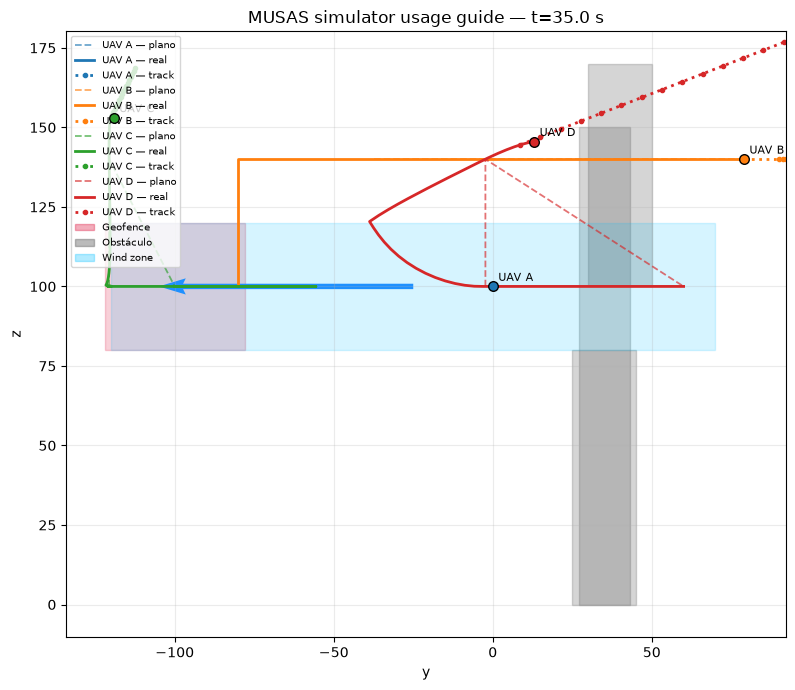

Image saved to: outputs/simulator_usage_guide_xy.png


In [169]:
IMAGE_PATH = OUTPUT_DIRECTORY / "simulator_usage_guide_xy.png"

figure = plot_dataset(
    DATASET_PATH,
    config=VisualizationConfig(
        view="yz",
        show_real_trajectories=True,
        show_flight_plans=True,
        show_tracks=True,
        show_sensor_reports=False,
        show_obstacles=True,
        show_geofences=True,
        show_wind_zones=True,
        title="MUSAS simulator usage guide",
    ),
    timestamp=35.0,
    output_path=IMAGE_PATH,
)
plt.show()
print("Image saved to:", IMAGE_PATH)


## 20. Animação

`frame_step` controla a distância temporal entre quadros e `fps` controla a velocidade de reprodução. Um `fps` menor produz uma animação visualmente mais lenta.


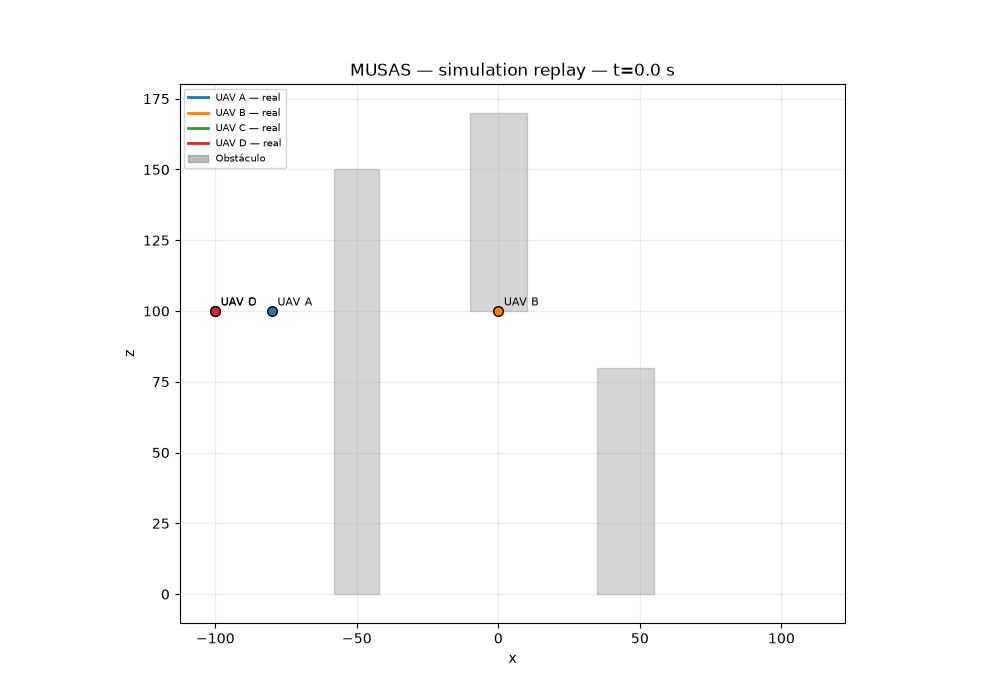

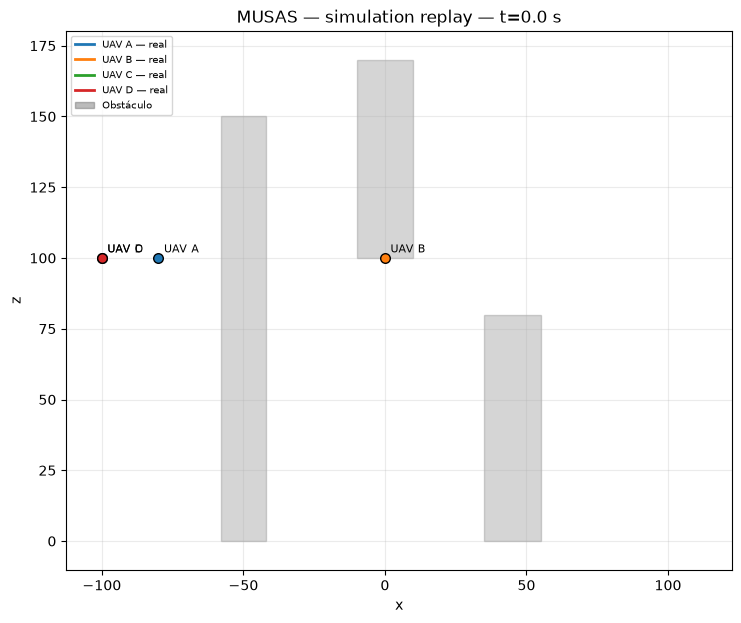

In [170]:
ANIMATION_PATH = OUTPUT_DIRECTORY / "simulator_usage_guide.gif"

animation = animate_dataset(
    DATASET_PATH,
    config=VisualizationConfig(
        view="xz",
        show_real_trajectories=True,
        show_flight_plans=True,
        show_tracks=True,
        show_sensor_reports=False,
        show_obstacles=True,
        show_geofences=True,
        show_wind_zones=True,
        frame_step=1.0,
        title="MUSAS — simulation replay",
    ),
    output_path=ANIMATION_PATH,
    fps=5,
)

display(Image(filename=ANIMATION_PATH))


## 21. Próximos passos

A partir deste modelo, o usuário pode substituir independentemente qualquer algoritmo, acrescentar obstáculos e wind zones, executar cenários maiores e comparar configurações usando os mesmos datasets e métricas.

Para desabilitar o SD, passe `None` para os dois algoritmos estratégicos. Para desabilitar o TD, omita tracking e os dois algoritmos táticos.
